# Supervised learning: continued

In [34]:
from sklearn.model_selection import train_test_split
from sklearn import datasets

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd

plt.style.use("ggplot")
# plt.rcParams["figure.dpi"] = 100
# font = {"family": "sans-serif", "size": 12}

# mpl.rc("font", **font)

## *k*NN regression

- Unlike *k*NN classification, where the output is a class label, *k*NN regression predicts a numerical value based on the average (or sometimes weighted average) of the target values of the $k$ nearest neighbors.

1. Choose the Number of Neighbors $k$
2. Find its $k$-nearest Neighbors (Eucledian distance is often used)
3. Compute the Predicted Value by taking the mean of the target values of the $k$-nearest neighbors.

$$
\hat{y} = \frac{1}{k} \sum_{i=1}^k y_i
$$

Another possibility: take weighted average where closer neighbors having more influence
$$
\hat{y} = \frac{\sum_{i=1}^k w_i y_i}{\sum_{i=1}^k w_i}, \quad w_i = \frac{1}{\text{distance to neighbor}_i}
$$

*Features*:
- Simple
- **Non-parametric**: No assumptions about the underlying data distribution. Important!
- Works well with both linear and non-linear relationships.
- But it's computationally expensive



![](images/threeNNregression.png)



Mean-squared error ([Scikit documentation](https://scikit-learn.org/stable/modules/model_evaluation.html#mean-squared-error))

If $y_i$: Actual value, $\hat{y}_i$: Predicted value

$$
\text{MSE}(y, \hat{y}) = \frac{1}{n_\text{samples}} \sum_{i=0}^{n_\text{samples} - 1} (y_i - \hat{y}_i)^2.
$$

$R^2$ score (**coefficient of determination**)

$$
R^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}
$$

Where:

Residual Sum of Squares

$$
  \text{SS}_{\text{res}} = \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2
$$



Total Sum of Squares

$$
  \text{SS}_{\text{tot}} = \sum_{i=1}^{n} \left( y_i - \bar{y} \right)^2
$$

In [35]:
np.random.seed(70)
np.random.randn(1,10)

array([[ 0.85099741,  0.17775492, -0.85303971, -0.44389968, -0.20293796,
         1.10051557, -3.03513615, -0.41456145, -1.34308784, -0.7731739 ]])

Mean Squared Error: 5.854038551615032
R-squared: 0.9903039677369723


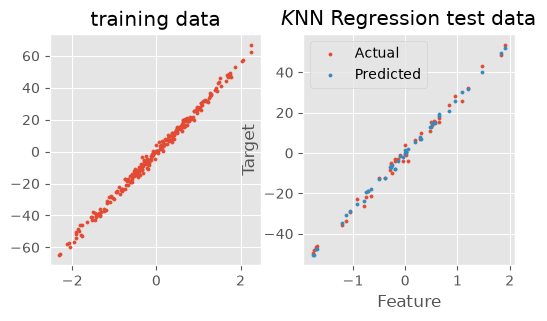

In [36]:
from sklearn.datasets import make_regression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Synthetic dataset
X, y = make_regression(n_samples=300, n_features=1, noise=2, random_state=7)
# X,y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=9
)

# training
knn_regressor = KNeighborsRegressor(n_neighbors=3)
knn_regressor.fit(X_train, y_train)

# predictions
y_pred = knn_regressor.predict(X_test)

# performance

print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred)}")
print(f"R-squared: {r2_score(y_test, y_pred)}")

fig, ax = plt.subplots(1,2,figsize=(6,3))
ax[0].scatter(X_train,y_train,s=5)
ax[0].set_title('training data')

ax[1].scatter(X_test, y_test, s=5, label="Actual")
ax[1].scatter(X_test, y_pred, s=5,label="Predicted")
ax[1].set_title("$K$NN Regression test data")
ax[1].set_xlabel("Feature")
ax[1].set_ylabel("Target")
ax[1].legend()
pass;

## Linear regression

- Ordinary Linear  (OLS)
  
The simplest regression method. It finds the slope and the intercept by minimizing MSE between predictions and true target values in the training set. 


0.25
Slope = [29.49488324]
Intercept = -1.160492334089445
Training set score: 0.68
Test set score = 0.6341552930964305
Mean Squared Error: 306.78530909578484
$R^2$= 0.6341552930964305


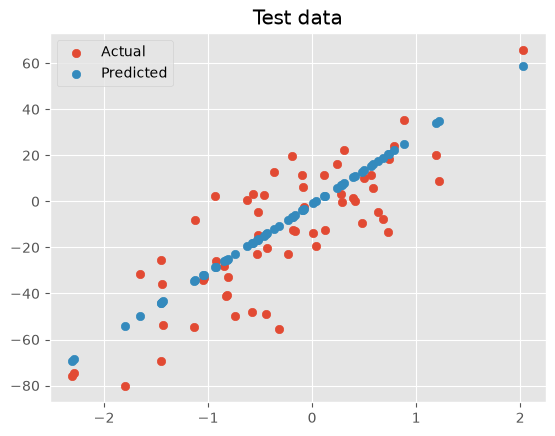

In [37]:
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression

# Synthetic dataset
X, y = make_regression(n_samples=300, n_features=1, noise=20, random_state=7)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2,random_state=42)
print(len(X_test)/len(X_train))
lr = LinearRegression().fit(X_train, y_train)

y_pred = lr.predict(X_test)

print(
    f"Slope = {lr.coef_}",
)
print(f"Intercept = {lr.intercept_}")

print("Training set score: {:.2f}".format(lr.score(X_train, y_train)))
print(f"Test set score = {lr.score(X_test, y_test)}")

print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred)}")
print(r"$R^2$" f"= {r2_score(y_test, y_pred)}")

# plt.scatter(X_train,y_train)
plt.scatter(X_test, y_test, label="Actual")
plt.scatter(X_test, y_pred, label="Predicted")
plt.title("Test data")
plt.legend()
pass;
# $R^2$ is low but both the training  and test sets have similar values. Possible underfitting (not overfitting).

## Let's now work with a more complicated diabetes data

In [38]:
diabetes = datasets.load_diabetes()
diabetes.keys()
# print(diabetes["DESCR"])

dict_keys(['data', 'target', 'frame', 'DESCR', 'feature_names', 'data_filename', 'target_filename', 'data_module'])

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    diabetes.data, diabetes.target, random_state=0
)

## Multiple linear regression

$$
\min_w \sum_{i=1}^{n} (y_i - X_i w)^2
$$

In [40]:
lr = LinearRegression().fit(X_train, y_train)

y_pred = lr.predict(X_test)

print(f"Coefficients = {lr.coef_}")
print(f"Intercept = {lr.intercept_}")

print(f"Training set r2 score = {lr.score(X_train, y_train):.2f}")
print(f"Test set r2 score = {lr.score(X_test, y_test):.2f}")

print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred):.2f}")
pass

Coefficients = [ -43.26198867 -208.66589855  593.40654802  302.89100542 -560.19094014
  261.40753499   -8.86674758  135.93174293  703.18354112   28.34977176]
Intercept = 153.06786205925664
Training set r2 score = 0.56
Test set r2 score = 0.36
Mean Squared Error: 3180.16


## Coefficient of Determination $R^2$

The $R^2$ measures how well a regression model explains the variance in the target variable.

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$
where: $y_i$ = actual value, $\hat{y}_i$ = predicted value, $\bar{y}$ = mean of actual values

- $R^2 = 1$ -> perfect predictions
- $R^2 = 0$ -> no better than predicting the mean
- $R^2 < 0$ -> worse than predicting the mean

`sklearn.metrics.r2_score()` calculates the same $R^2$ formula above.


In [41]:
def r2_score(y, y_pred):
    y_mean = sum(y) / len(y)
    ss_res = sum((a - p) ** 2 for a, p in zip(y, y_pred))
    ss_tot = sum((a - y_mean) ** 2 for a in y)
    return 1 - ss_res / ss_tot
y = [1, 2, 3, 4, 5]
y_pred = [1, 2, 3, 5, 4]

print(r2_score(y, y_pred))

0.8


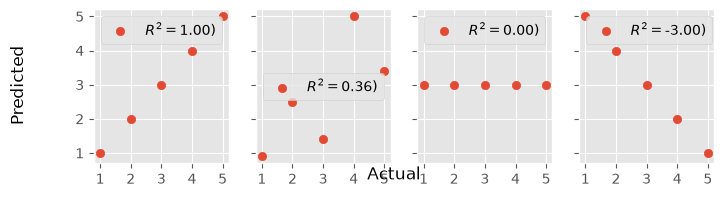

In [42]:
from sklearn.metrics import r2_score

y = [1, 2, 3, 4, 5]

pred = {
    "perfect":  [1, 2, 3, 4, 5],
    "ok": [.9, 2.5, 1.4, 5, 3.4],
    "mean": [3, 3, 3, 3, 3],
    "poor":   [5, 4, 3, 2, 1]
}
fig,ax=plt.subplots(1,4,figsize=(8,2),sharex=True,sharey=True)

count = 0
for name, p in pred.items():
    ax[count].scatter(y, p, label=f"$R^2=${r2_score(y,p):.2f})")
    ax[count].legend()
    ax[count].set_xticks(y)
    ax[count].set_yticks(y)
    count+=1

fig.supxlabel("Actual")
fig.supylabel("Predicted");


## Ridge regression

- See for good discussion of regressions: https://www.youtube.com/playlist?list=PLvcbYUQ5t0UFhdkiCojiFOygmbMU19BFq
- For bias–variance tradeoff in ridge regression: https://pages.hmc.edu/ruye/MachineLearning/lectures/ch7/node11.html

Linear regression with an **L2 regularization** term to prevent overfitting by penalizing large coefficients. It's useful when there are **many correlated features** in the dataset. (See: https://www.ibm.com/think/topics/ridge-regression and https://www.statlect.com/fundamentals-of-statistics/ridge-regression)

$$
\min_{ \beta \in \mathbb{R}^p } \left\{ \frac{1}{N} \left\| y - X \beta \right\|_2^2 + \lambda \| \beta \|_2^2 \right\}
$$
where $\| u \|_p = \biggl( \sum_{i=1}^N | u_i |^p \biggr)^{1/p}$.

$\lambda$ is the regularization parameter (controls the strength of penalty). A higher $\lambda$ shrinks the coefficients towards zero, reducing model complexity. It **does not eliminate features**, though.


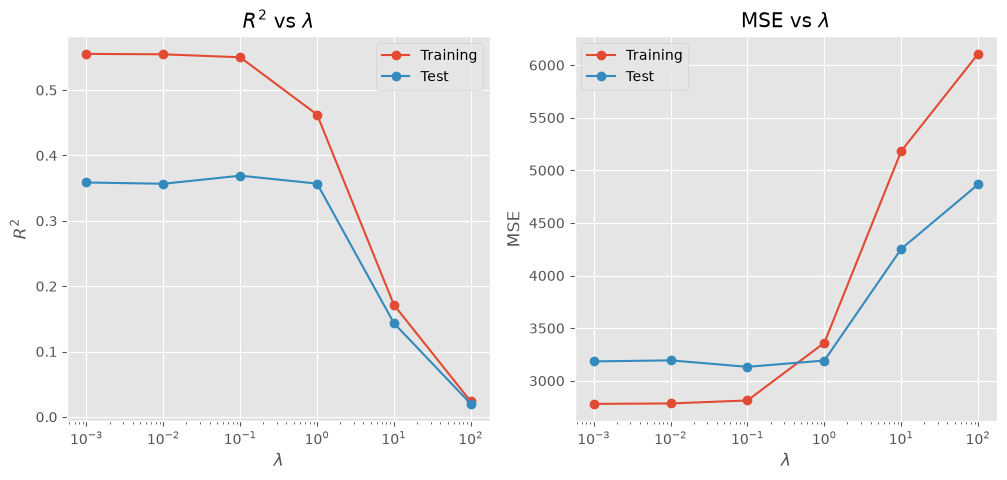

In [43]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# lambda = 0 is OLS for Ridge

lambda_values = [0.001, 0.01, 0.1, 1, 10, 100]

X_train, X_test, y_train, y_test = train_test_split(
    diabetes.data, diabetes.target, random_state=0
)

training_score = []
test_score = []
training_mse = []
test_mse = []

for val in lambda_values:
    ridge = Ridge(alpha=val).fit(X_train, y_train)

    y_pred_train = ridge.predict(X_train)
    y_pred_test = ridge.predict(X_test)

    train_score = ridge.score(X_train, y_train)
    tst_score = ridge.score(X_test, y_test)

    train_mse_val = mean_squared_error(y_train, y_pred_train)
    test_mse_val = mean_squared_error(y_test, y_pred_test)

    training_score.append(train_score)
    test_score.append(tst_score)
    training_mse.append(train_mse_val)
    test_mse.append(test_mse_val)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# R^2 plot
axes[0].plot(lambda_values, training_score, marker="o", label="Training")
axes[0].plot(lambda_values, test_score, marker="o", label="Test")
axes[0].set_xscale("log")
axes[0].set_ylabel(r"$R^2$")
axes[0].set_xlabel(r"$\lambda$")
axes[0].set_title(r"$R^2$ vs $\lambda$")
axes[0].legend()

# MSE plot
axes[1].plot(lambda_values, training_mse, marker="o", label="Training")
axes[1].plot(lambda_values, test_mse, marker="o", label="Test")
axes[1].set_xscale("log")
axes[1].set_ylabel("MSE")
axes[1].set_xlabel(r"$\lambda$")
axes[1].set_title(r"MSE vs $\lambda$")
axes[1].legend();

- $\lambda$ controls model complexity by penalizing large coefficients
- $\lambda=0$ is plain OLS, no penalty
- Small $\lambda$ -> large coefficients, fits training data closely, risks overfitting
- Large $\lambda$ shrinks coefficients toward zero, simplifies the model, risks underfitting
- Test $R^2$ and test MSE are flat and optimal from $\lambda = 0.001$ to $\lambda = 0.1$: no gain from smaller $\lambda$ values
- At $\lambda = 1$, test performance starts declining ($R^2$ drops, MSE rises)
- At $\lambda = 100$, performance collapses ($R^2 \approx 0$): model is underfitting
- Optimal $\lambda = 0.1$: largest $\lambda$ in the flat region, giving maximum regularization benefit (more stable, robust coefficients) without sacrificing any test accuracy

## Lasso Regression

Linear regression that includes **L1 regularization** to reduce overfitting and perform **feature selection** by shrinking some coefficients to exactly **zero**. (unlike Ridge!)

$$
\min_{ \beta \in \mathbb{R}^p } \left\{ \frac{1}{N} \left\| y - X \beta \right\|_2^2 + \lambda \| \beta \|_1 \right\}
$$


**Works well when there are many features**, especially if only a few are important.

Lower $\lambda$ allows more non-zero coefficient


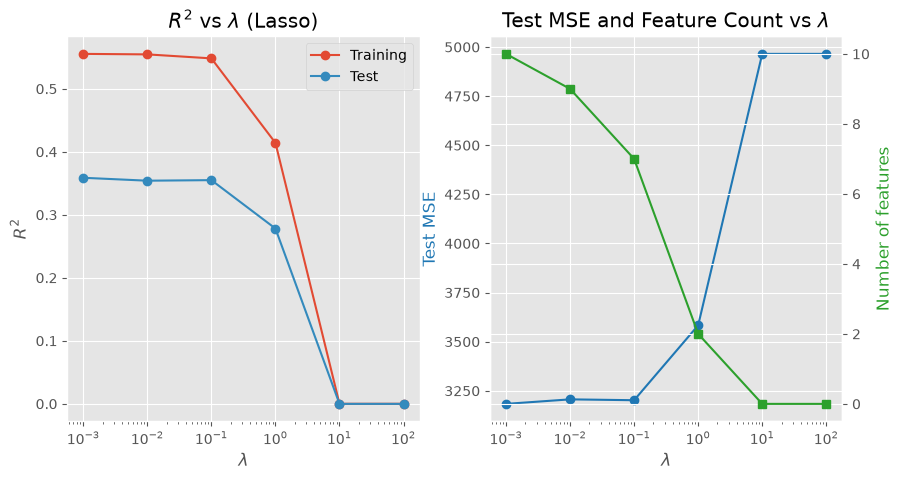

In [44]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error

training_score = []
test_score = []
training_mse = []
test_mse = []
n_features = []

for val in lambda_values:
    lasso = Lasso(alpha=val, max_iter=100000).fit(X_train, y_train)

    y_pred_train = lasso.predict(X_train)
    y_pred_test = lasso.predict(X_test)

    train_score = lasso.score(X_train, y_train)
    tst_score = lasso.score(X_test, y_test)

    train_mse_val = mean_squared_error(y_train, y_pred_train)
    test_mse_val = mean_squared_error(y_test, y_pred_test)

    training_score.append(train_score)
    test_score.append(tst_score)
    training_mse.append(train_mse_val)
    test_mse.append(test_mse_val)
    n_features.append(np.sum(lasso.coef_ != 0))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].plot(lambda_values, training_score, marker="o", label="Training")
axes[0].plot(lambda_values, test_score, marker="o", label="Test")
axes[0].set_xscale("log")
axes[0].set_ylabel(r"$R^2$")
axes[0].set_xlabel(r"$\lambda$")
axes[0].set_title(r"$R^2$ vs $\lambda$ (Lasso)")
axes[0].legend()

axes[1].plot(lambda_values, test_mse, marker="o", color="tab:blue", label="Test MSE")
ax2 = axes[1].twinx()
ax2.plot(lambda_values, n_features, marker="s", color="tab:green", label="Num of Features")
axes[1].set_xscale("log")
axes[1].set_ylabel("Test MSE", color="tab:blue")
ax2.set_ylabel("Number of features", color="tab:green")
axes[1].set_xlabel(r"$\lambda$")
axes[1].set_title(r"Test MSE and Feature Count vs $\lambda$");

- Small $\lambda$: most features kept, close to OLS, risk of overfitting
- Large $\lambda$: coefficients driven to exactly $0$, fewer active features: helps in feature selection
- Training $R^2$ decreases monotonically as $\lambda$ increases (less model freedom)
- Very large $\lambda$ can force $w \to 0$, reducing the model to predicting $\bar{y}$
- $\lambda=0.1$ is a good choice.

## Rough guidelines
- First try ridge regression
- If you have a large amount of features and expect only a few of them to be  important, try Lasso.
- Also, use LASSO if you want an interpretable model.

## Logistic regression

See: https://www.youtube.com/watch?v=d_bynTkE9yY

- A supervised learning algorithm used for **classification**, despite its name. It predicts the probability that an input belongs to a given class, which is then converted to a label. It's commonly used for binary classification.
- Uses a sigmoid function to map input values to probabilities. 
    - A general logistic function: $f(x) = \frac{L}{1 + e^{-k(x -x_0)}}$
    - Standard sigmoid function ($L=1, k=1, x_0=0$ in logistic function): $f(x) = \frac{1}{1 + e^{-x}}$

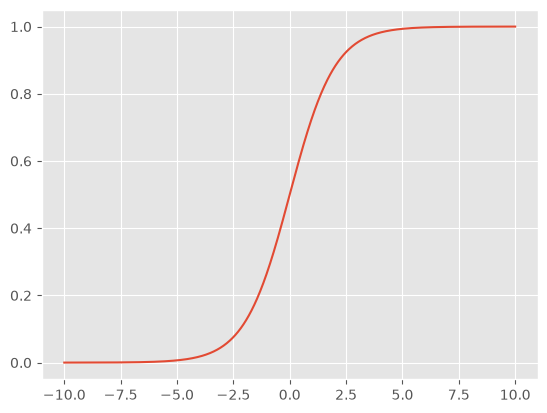

In [45]:
x = np.linspace(-10,10,1000)
plt.plot(x,1/(1+np.exp(-x)))

- Logistic regression first computes a linear combination of the inputs, similar to linear regression: $z_i = X_i w + w_0$
    - And then passes it through the sigmoid to get a probability:
$\hat{p}(X_i) = \sigma(z_i) = \frac{1}{1 + \exp(-(X_i w + w_0))}$
- Unlike linear regression, there is *no closed-form solution* for logistic regression's weights. Instead, weights are learned iteratively
- *Classification step*: probability > 0.5 : class 1, else class 0.


### Loss function

Cross-entropy measures *difference* between two probability distributions. It's often used as a loss function in classification problems to quantify how well the predicted probabilities match the actual class labels.
    - For binary classification, the cross-entropy loss is: $- \frac{1}{m} \sum_{i=1}^{m} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$
    - $m$: number of samples; $y_i$: true label; $\hat{y}_i$ : predicted probability for class 1 (from the model)
- If the model predicts a high probability for the correct class, the loss will be small.
- If the model predicts a high probability for the wrong class, the loss will be large.

| True label $y_i$ | Predicted $\hat{y}_i$ | Loss contribution |
|---|---|---|
| 1 | 0.99 (confident, correct) | small |
| 1 | 0.01 (confident, wrong) | large |
| 0 | 0.01 (confident, correct) | small |
| 0 | 0.99 (confident, wrong) | large |


0.2231435513142097
1.6094379124341003


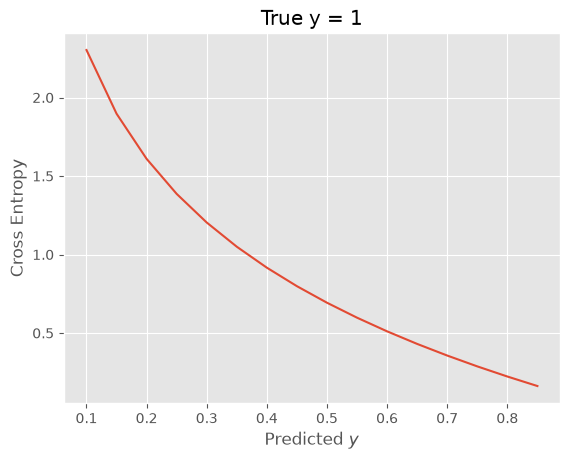

In [46]:
def binary_cross_entropy(y_true, y_pred):
    loss = -(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    return loss


# correct prediction
y_true_1 = 1
y_pred_1 = 0.8  # Predicted probability for class 1
print(binary_cross_entropy(y_true_1, y_pred_1))

# incorrect prediction
y_true_2 = 1
y_pred_2 = 0.2  # Predicted probability for class 1
print(binary_cross_entropy(y_true_2, y_pred_2))

x = np.arange(0.1, 0.9, 0.05)
cent = []
for _ in x:
    cent.append(binary_cross_entropy(1, _))
# cent
plt.plot(x, cent)
plt.ylabel("Cross Entropy")
plt.xlabel("Predicted $y$")
plt.title("True y = 1");

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

Accuracy: 0.95


array([0, 0])

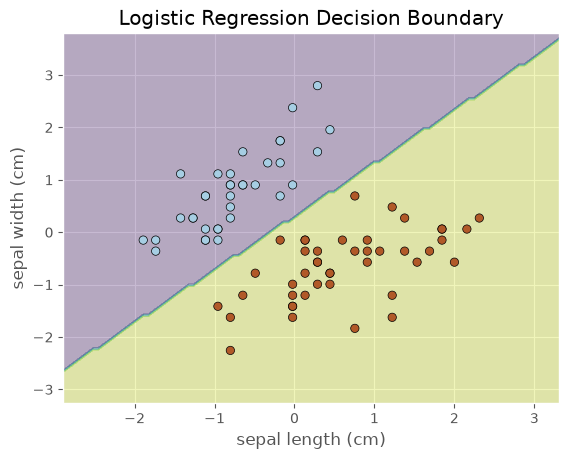

In [47]:
# https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
# also: https://online.stat.psu.edu/stat462/node/207/
# read about scikit learn's documentation. for example, it applies a regularization by default while it's not strictly necessary, but helps in numerical stability.

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# accuracy score (counts exact matches)
# >>> y_pred = [0, 2, 1, 3]
# >>> y_true = [0, 1, 2, 3]
# >>> accuracy_score(y_true, y_pred)
# 0.5

iris = datasets.load_iris()

# using only two classes for visualization (Setosa & Versicolor)
# think about how will you modify the code and visualize it: 1) for more than two classes and 2) more than 2 properties
# first 100 samples (0 = Setosa, 1 = Versicolor)
X = iris.data[:100, :2]
y = iris.target[:100]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)

# standardize features. read up the difference between fit_trasform and transform. (we want to standardize features using train data, not test data -- we want to avoid data leakage)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

model.predict([[1, 2], [1, 3]])


# disclaimer: part of the code is generated by chatgpt!
def plot_decision_boundary(X, y, model):

    # define range of the two features
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    # create a 100x100 grid of points
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

    # predict the class for all grid points
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    # make the predicted classes a 2D grid, too
    Z = Z.reshape(xx.shape)
    # color the regions as per predicted class
    plt.contourf(xx, yy, Z, alpha=0.3)
    # plot data points
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k", cmap=plt.cm.Paired)
    plt.xlabel(iris.feature_names[0])
    plt.ylabel(iris.feature_names[1])
    plt.title("Logistic Regression Decision Boundary")
    plt.show()


plot_decision_boundary(X_train, y_train, model)